# ConjunctivaGuard PoC, Part 3: the eyelid finder (module M2)

**Goal:** teach a model to draw the **inner-eyelid mask** on a full face photo (dataset D03).

**Before you start: turn on the GPU** (a fast chip for training): menu **Runtime → Change runtime type → T4 GPU → Save**.

Run the cells top to bottom with ▶. Total time about 15–25 minutes, mostly waiting.

**Words from the lesson:** *model* (millions of adjustable numbers), *training* (guess → measure the mistake → adjust → repeat), *loss* (size of the mistake), *epoch* (one pass over all training photos), *transfer learning* (start from a model that already "sees"), *Dice* (mask overlap: 0 none, 1 perfect).

### Cell 1: setup
Connects Drive and checks the GPU. The first time, it downloads D03 (4.6 GB, about 1–2 minutes) and unpacks it. After Cell 3 has run once, a small copy is kept in your Drive and the download is skipped.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, zipfile, gdown, torch

D03_LINK_ID = 'YOUR_D03_FILE_ID'          # your D03_Segmentation.zip
OUT = '/content/drive/MyDrive/ConjunctivaGuard/poc_outputs'   # results are kept here
os.makedirs(OUT, exist_ok=True)
CACHE = os.path.join(OUT, 'D03_small.npz')                    # small copy of D03 (made in Cell 3)

print('GPU available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    print('-> Turn on the GPU: Runtime > Change runtime type > T4 GPU > Save, then run this cell again.')

D03_DIR = None
if os.path.exists(CACHE):
    print('Small copy of D03 found in Drive: no download needed.')
else:
    if not os.path.exists('/content/D03.zip'):
        gdown.download(id=D03_LINK_ID, output='/content/D03.zip', quiet=False)
    if not os.path.exists('/content/work/D03'):
        with zipfile.ZipFile('/content/D03.zip') as zf:
            zf.extractall('/content/work/D03')
    D03_DIR = glob.glob('/content/work/D03/*/')[0]
    print('Folders:', sorted(os.listdir(D03_DIR)))

Mounted at /content/drive
GPU available: True


Downloading...
From (original): https://drive.google.com/uc?id=YOUR_D03_FILE_ID
From (redirected): https://drive.google.com/uc?id=YOUR_D03_FILE_ID&confirm=t&uuid=...
To: /content/D03.zip
100%|██████████| 4.58G/4.58G [01:07<00:00, 67.5MB/s]


Folders: ['Images', 'Masks Annotator 1', 'Masks Annotator 2']


### Cell 2: install the model library
`segmentation-models-pytorch` gives us ready-made mask models such as **LinkNet** (the one named in your proposal). About 20 seconds.

In [ ]:
!pip install -q segmentation-models-pytorch
import segmentation_models_pytorch as smp
print('Library ready, version', smp.__version__)

Library ready, version 0.6.0


### Cell 3: make the photos small
The photos are huge (3072 × 4096). Training on them would be very slow, so we shrink every photo and both masks to **288 × 384** (same shape, 3:4). The masks are red-on-black pictures; we turn them into 1 (eyelid) and 0 (not eyelid).

The first time this takes about 5–8 minutes. The result is saved in Drive (`D03_small.npz`), so next time it loads in seconds.

In [ ]:
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

W, H = 288, 384

def load_photo(path):
    im = Image.open(path).convert('RGB')
    return np.asarray(im.resize((W, H), Image.BILINEAR))

def load_mask(path):
    m = np.asarray(Image.open(path).convert('RGB').resize((W, H), Image.NEAREST))
    return (m.max(axis=2) > 50).astype(np.uint8)        # coloured pixel = eyelid = 1

def number(f):
    s = os.path.splitext(f)[0]
    return int(s) if s.isdigit() else 10**9

if os.path.exists(CACHE):
    z = np.load(CACHE)
    X, M1, M2, names = z['X'], z['M1'], z['M2'], list(z['names'])
else:
    img_dir = os.path.join(D03_DIR, 'Images')
    a1_dir = os.path.join(D03_DIR, 'Masks Annotator 1')
    a2_dir = os.path.join(D03_DIR, 'Masks Annotator 2')
    names = [f for f in sorted(os.listdir(img_dir), key=number)
             if os.path.exists(os.path.join(a1_dir, f)) and os.path.exists(os.path.join(a2_dir, f))]
    X  = np.stack([load_photo(os.path.join(img_dir, f)) for f in tqdm(names, desc='photos')])
    M1 = np.stack([load_mask(os.path.join(a1_dir, f))  for f in tqdm(names, desc='annotator 1')])
    M2 = np.stack([load_mask(os.path.join(a2_dir, f))  for f in tqdm(names, desc='annotator 2')])
    np.savez_compressed(CACHE, X=X, M1=M1, M2=M2, names=np.array(names))

print('Photos:', X.shape, '| masks:', M1.shape)
print(f'Eyelid is on average {100 * M1.mean():.1f}% of the photo')

photos:   0%|          | 0/547 [00:00<?, ?it/s]

annotator 1:   0%|          | 0/547 [00:00<?, ?it/s]

annotator 2:   0%|          | 0/547 [00:00<?, ?it/s]

Photos: (547, 384, 288, 3) | masks: (547, 384, 288)
Eyelid is on average 0.8% of the photo


### Cell 4: check that photo and mask line up
Shows 3 photos with annotator 1's mask painted **green**. The green must sit exactly on the inner eyelid. If it is somewhere else, stop and note it.

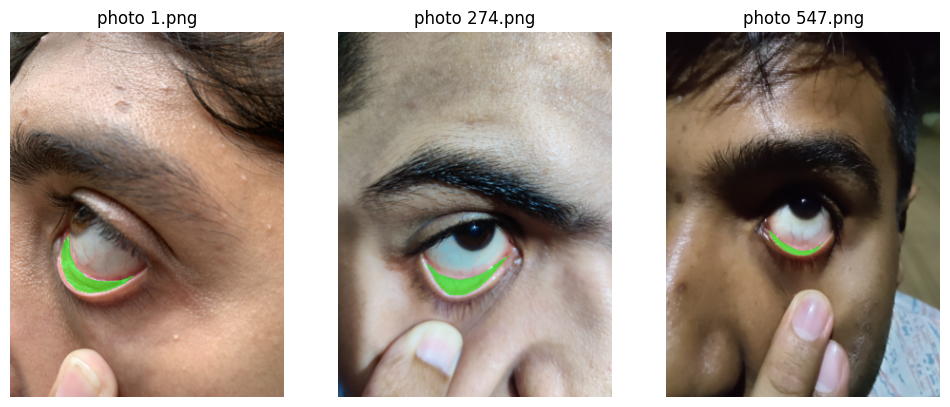

In [ ]:
import matplotlib.pyplot as plt

def paint(img, mask, colour=(0, 255, 0)):
    out = img.copy().astype(np.float32)
    out[mask == 1] = 0.45 * out[mask == 1] + 0.55 * np.array(colour)
    return out.astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, i in zip(axes, [0, len(names) // 2, len(names) - 1]):
    ax.imshow(paint(X[i], M1[i])); ax.set_title('photo ' + names[i]); ax.axis('off')
plt.show()

### Cell 5: split the 547 photos
Same idea as Part 2: **train** (study) 70%, **validation** (practice test) 15%, **test** (final exam) 15%, with seed 42 so it is the same every time. The test photos are never used for training.

In [ ]:
import pandas as pd

rng = np.random.default_rng(42)
order = rng.permutation(len(names))
n_test = round(0.15 * len(order)); n_val = round(0.15 * len(order))
test_idx, val_idx, train_idx = order[:n_test], order[n_test:n_test + n_val], order[n_test + n_val:]

split = np.array(['train'] * len(names), dtype=object)
split[val_idx] = 'val'; split[test_idx] = 'test'
pd.DataFrame({'photo': names, 'split': split}).to_csv(os.path.join(OUT, 'D03_splits.csv'), index=False)
print('train', len(train_idx), '| val', len(val_idx), '| test', len(test_idx))

train 383 | val 82 | test 82


### Cell 6: how much do two humans agree?
Two people drew masks for the same photos. Their **Dice** score shows how well humans agree. This is our target: if the model gets close to it, it is about as good as a person.

In [ ]:
def dice(a, b):
    a = a.astype(bool); b = b.astype(bool)
    total = a.sum() + b.sum()
    return 1.0 if total == 0 else 2.0 * (a & b).sum() / total

human = np.array([dice(M1[i], M2[i]) for i in test_idx])
print(f'Human agreement on test photos (annotator 1 vs 2): Dice {human.mean():.3f}  (lowest {human.min():.3f})')

Human agreement on test photos (annotator 1 vs 2): Dice 0.726  (lowest 0.410)


### Cell 7: train the eyelid finder (about 5 minutes on the GPU)
**LinkNet** with a **ResNet-34** "eye" that already learned to see from millions of everyday photos (transfer learning). It learns from annotator 1's masks.

Each line is one **epoch**. Watch two numbers:
- **loss** (the mistake on training photos) should go **down**;
- **validation Dice** (overlap on practice photos it does not learn from) should go **up**.

The best version is saved to your Drive as `M2_eyelid_linknet.pt`.

In [ ]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(42); np.random.seed(42)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)   # colour settings the pretrained model expects
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

class EyelidSet(Dataset):
    def __init__(self, ids, train):
        self.ids, self.train = ids, train
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]
        x = X[i].astype(np.float32) / 255.0
        y = M1[i].astype(np.float32)
        if self.train and np.random.rand() < 0.5:          # mirror half the training photos
            x, y = x[:, ::-1], y[:, ::-1]
        x = (x - MEAN) / STD
        return torch.from_numpy(x.transpose(2, 0, 1).copy()), torch.from_numpy(y[None].copy())

train_dl = DataLoader(EyelidSet(train_idx, True), batch_size=8, shuffle=True)

model = smp.Linknet('resnet34', encoder_weights='imagenet', classes=1).to(dev)
dice_loss = smp.losses.DiceLoss('binary')
bce = nn.BCEWithLogitsLoss()
opt = torch.optim.Adam(model.parameters(), lr=3e-4)

def predict_masks(ids):
    model.eval(); out = []
    with torch.no_grad():
        for xb, _ in DataLoader(EyelidSet(ids, False), batch_size=8):
            out.append((torch.sigmoid(model(xb.to(dev))) > 0.5).cpu().numpy()[:, 0])
    return np.concatenate(out).astype(np.uint8)

MODEL_PATH = os.path.join(OUT, 'M2_eyelid_linknet.pt')
EPOCHS, history, best = 15, [], -1.0
for ep in range(1, EPOCHS + 1):
    model.train(); losses = []
    for xb, yb in train_dl:
        xb, yb = xb.to(dev), yb.to(dev)
        logits = model(xb)
        loss = dice_loss(logits, yb) + bce(logits, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        losses.append(loss.item())
    pv = predict_masks(val_idx)
    vd = float(np.mean([dice(p, M1[i]) for p, i in zip(pv, val_idx)]))
    history.append((ep, float(np.mean(losses)), vd))
    note = ''
    if vd > best:
        best = vd; torch.save(model.state_dict(), MODEL_PATH); note = '  <- best so far, saved'
    print(f'epoch {ep:2d} | loss {np.mean(losses):.3f} | validation Dice {vd:.3f}{note}')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch  1 | loss 1.545 | validation Dice 0.500  <- best so far, saved
epoch  2 | loss 1.266 | validation Dice 0.683  <- best so far, saved
epoch  3 | loss 1.154 | validation Dice 0.769  <- best so far, saved
epoch  4 | loss 1.091 | validation Dice 0.727
epoch  5 | loss 1.041 | validation Dice 0.792  <- best so far, saved
epoch  6 | loss 0.994 | validation Dice 0.812  <- best so far, saved
epoch  7 | loss 0.950 | validation Dice 0.816  <- best so far, saved
epoch  8 | loss 0.906 | validation Dice 0.758
epoch  9 | loss 0.858 | validation Dice 0.835  <- best so far, saved
epoch 10 | loss 0.804 | validation Dice 0.843  <- best so far, saved
epoch 11 | loss 0.740 | validation Dice 0.844  <- best so far, saved
epoch 12 | loss 0.676 | validation Dice 0.840
epoch 13 | loss 0.599 | validation Dice 0.860  <- best so far, saved
epoch 14 | loss 0.522 | validation Dice 0.867  <- best so far, saved
epoch 15 | loss 0.442 | validation Dice 0.867


### Cell 8: the learning curves
Left: the mistake (loss) going down. Right: the overlap on practice photos going up. When the right line stops rising, the model has learned what it can.

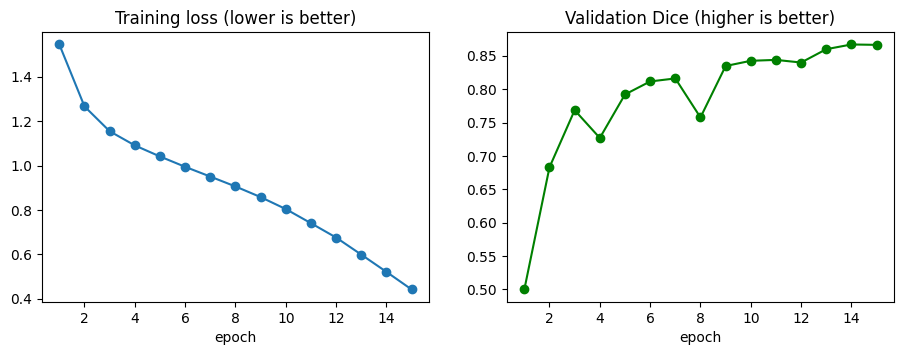

In [ ]:
h = np.array(history)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
a.plot(h[:, 0], h[:, 1], marker='o'); a.set_title('Training loss (lower is better)'); a.set_xlabel('epoch')
b.plot(h[:, 0], h[:, 2], marker='o', color='green'); b.set_title('Validation Dice (higher is better)'); b.set_xlabel('epoch')
plt.show()

### Cell 9: the final exam (test photos)
Loads the best saved model and scores it on the **test** photos it has never seen, against both annotators, next to the human agreement.

In [ ]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=dev))
pt = predict_masks(test_idx)
vs_a1 = np.array([dice(p, M1[i]) for p, i in zip(pt, test_idx)])
vs_a2 = np.array([dice(p, M2[i]) for p, i in zip(pt, test_idx)])

table = pd.DataFrame({
    'comparison': ['Model vs annotator 1', 'Model vs annotator 2', 'Human: annotator 1 vs 2'],
    'mean Dice':  [vs_a1.mean(), vs_a2.mean(), human.mean()],
    'lowest':     [vs_a1.min(), vs_a2.min(), human.min()],
}).round(3)
display(table)
weak = int((vs_a1 < 0.5).sum())
print(f'Test photos where the eyelid was found poorly (Dice < 0.5): {weak} of {len(test_idx)}')
print('-> in the full system, such photos would be REJECTED (no eyelid found = no result).')

,comparison,mean Dice,lowest
0,Model vs annotator 1,0.848,0.592
1,Model vs annotator 2,0.789,0.639
2,Human: annotator 1 vs 2,0.726,0.410


Test photos where the eyelid was found poorly (Dice < 0.5): 0 of 82
-> in the full system, such photos would be REJECTED (no eyelid found = no result).


### Cell 10: see the results
Each row: the photo, the human mask (green) and the model's mask (blue), with the model's Dice.

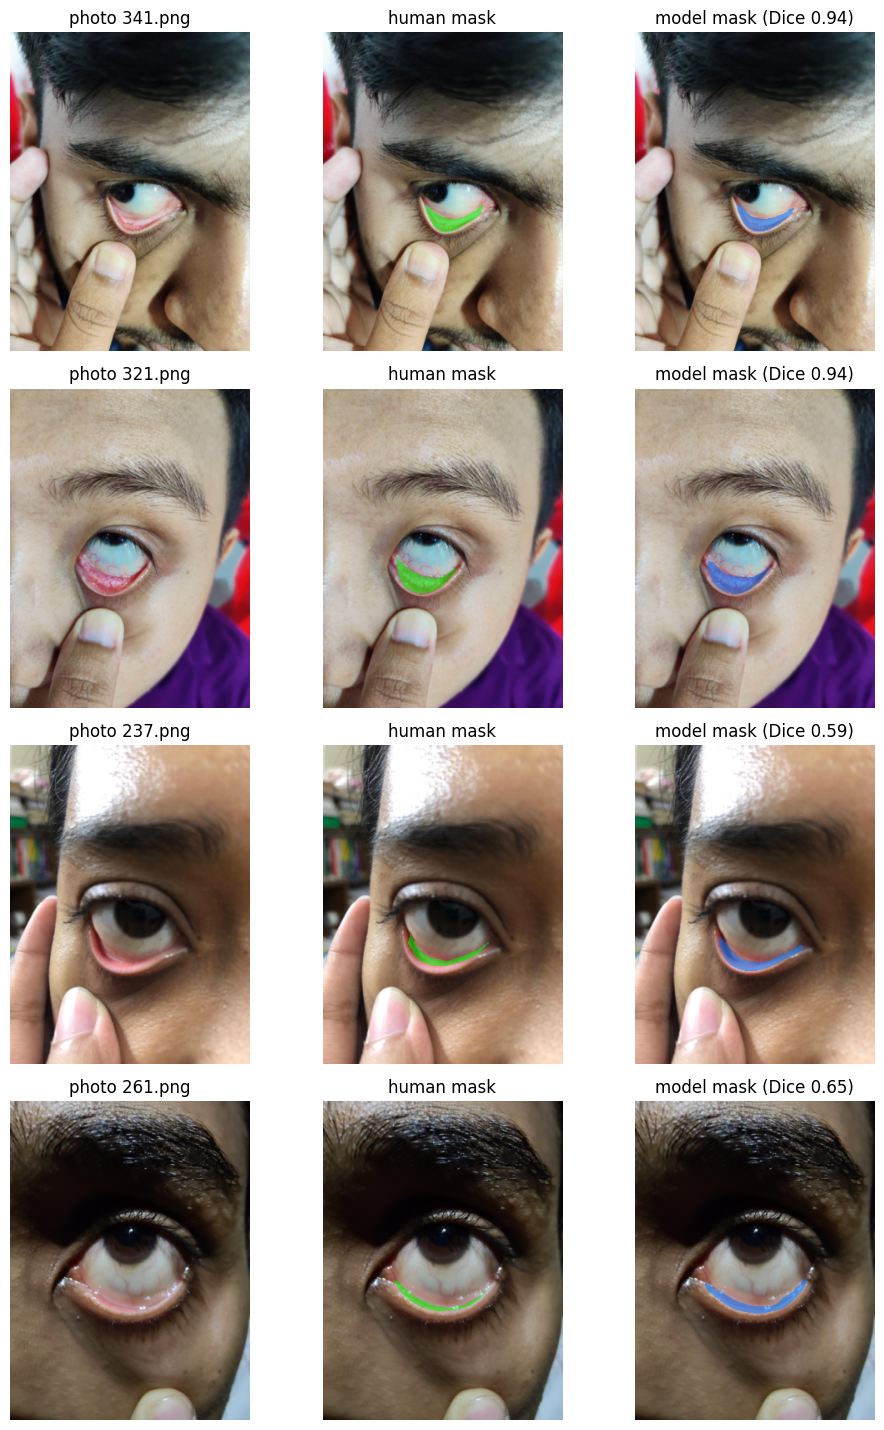

In [ ]:
show = list(test_idx[np.argsort(-vs_a1)[:2]]) + list(test_idx[np.argsort(vs_a1)[:2]])   # 2 best + 2 worst
fig, axes = plt.subplots(len(show), 3, figsize=(10, 3.6 * len(show)))
for row, i in zip(axes, show):
    k = list(test_idx).index(i)
    row[0].imshow(X[i]); row[0].set_title('photo ' + names[i])
    row[1].imshow(paint(X[i], M1[i])); row[1].set_title('human mask')
    row[2].imshow(paint(X[i], pt[k], (0, 120, 255))); row[2].set_title(f'model mask (Dice {vs_a1[k]:.2f})')
    for ax in row: ax.axis('off')
plt.tight_layout(); plt.show()

### Cell 11: save the results
Saves the scores so later parts (and your presentation) can use them.

In [ ]:
import json
res = {'photos': len(names), 'train': len(train_idx), 'val': len(val_idx), 'test': len(test_idx),
       'image_size': [W, H], 'epochs': EPOCHS, 'best_val_dice': round(best, 3),
       'test_dice_vs_annotator1': round(float(vs_a1.mean()), 3),
       'test_dice_vs_annotator2': round(float(vs_a2.mean()), 3),
       'human_agreement_dice': round(float(human.mean()), 3),
       'weak_test_photos_dice_below_0.5': weak}
json.dump(res, open(os.path.join(OUT, 'M2_results.json'), 'w'), indent=1)
pd.DataFrame(history, columns=['epoch', 'train_loss', 'val_dice']).to_csv(os.path.join(OUT, 'M2_history.csv'), index=False)
print(json.dumps(res, indent=1))

{
 "photos": 547,
 "train": 383,
 "val": 82,
 "test": 82,
 "image_size": [
  288,
  384
 ],
 "epochs": 15,
 "best_val_dice": 0.867,
 "test_dice_vs_annotator1": 0.848,
 "test_dice_vs_annotator2": 0.789,
 "human_agreement_dice": 0.726,
 "weak_test_photos_dice_below_0.5": 0
}


### Part 3 done ✅
**Outputs to check:** the text output of **Cells 6, 7, 9 and 11**, and screenshots of **Cell 4** and **Cell 10**.

**What you learned**
- **Training** = guess, measure the mistake (loss), adjust, repeat for many epochs.
- **Validation** picks the best version; **test** gives the honest final score.
- **Human agreement** is a fair target: a model close to it is about as good as a person.
- In ConjunctivaGuard, a photo where the eyelid is not found is **rejected**, never guessed.